We will treate the anomaly detection as a classification problem. We are going to use logistic regression to detect anomalies on the P1 channel. Since we are applying a classifier model, we need to train on the test set. The training data has no anomalies so it makes no sense to fit a classifier model to that data.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = np.load("../data/data/test/P-1.npy")
df = pd.DataFrame(df)
df

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,-0.695162,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.685704,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.725719,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.761368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.745362,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8500,0.293561,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8501,0.341579,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
8502,-0.316115,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8503,-0.297199,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
anomalies = pd.read_csv("../labeled_anomalies.csv")
anomalies

,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307
...,...,...,...,...,...
77,P-11,MSL,"[[1778, 1898], [1238, 1344]]","[point, point]",3535
78,D-15,MSL,"[[1500, 2140]]",[point],2158
79,D-16,MSL,"[[600, 1250]]",[contextual],2191
80,M-7,MSL,"[[940, 1040]]",[point],2156


In [4]:
anomalies_p1=anomalies[anomalies.chan_id=="P-1"]["anomaly_sequences"][0]

In [5]:
#Note that anomalies_p1  is acutally a string, so we convert it to a list of integers here
#We use ast to convert a string to a list
import ast
p1_anomalies = ast.literal_eval(anomalies_p1)
#Now we have a list of lists
p1_anomalies

[[2149, 2349], [4536, 4844], [3539, 3779]]

In [6]:
#We will store all the anomalous time stamps in a list
a_time = []
for i in p1_anomalies:
    a_time+=list(range(i[0],i[1]))
a_time

[2149,
 2150,
 2151,
 2152,
 2153,
 2154,
 2155,
 2156,
 2157,
 2158,
 2159,
 2160,
 2161,
 2162,
 2163,
 2164,
 2165,
 2166,
 2167,
 2168,
 2169,
 2170,
 2171,
 2172,
 2173,
 2174,
 2175,
 2176,
 2177,
 2178,
 2179,
 2180,
 2181,
 2182,
 2183,
 2184,
 2185,
 2186,
 2187,
 2188,
 2189,
 2190,
 2191,
 2192,
 2193,
 2194,
 2195,
 2196,
 2197,
 2198,
 2199,
 2200,
 2201,
 2202,
 2203,
 2204,
 2205,
 2206,
 2207,
 2208,
 2209,
 2210,
 2211,
 2212,
 2213,
 2214,
 2215,
 2216,
 2217,
 2218,
 2219,
 2220,
 2221,
 2222,
 2223,
 2224,
 2225,
 2226,
 2227,
 2228,
 2229,
 2230,
 2231,
 2232,
 2233,
 2234,
 2235,
 2236,
 2237,
 2238,
 2239,
 2240,
 2241,
 2242,
 2243,
 2244,
 2245,
 2246,
 2247,
 2248,
 2249,
 2250,
 2251,
 2252,
 2253,
 2254,
 2255,
 2256,
 2257,
 2258,
 2259,
 2260,
 2261,
 2262,
 2263,
 2264,
 2265,
 2266,
 2267,
 2268,
 2269,
 2270,
 2271,
 2272,
 2273,
 2274,
 2275,
 2276,
 2277,
 2278,
 2279,
 2280,
 2281,
 2282,
 2283,
 2284,
 2285,
 2286,
 2287,
 2288,
 2289,
 2290,
 2291,

In [7]:
#Let us make a new target column that gives 1 or 0 depending on if it an anomaly or not.
df["target"]= df.index.isin(a_time).astype(int)

In [8]:
df["target"].mean()*100

np.float64(8.79482657260435)

So roughly 8% of our timestamps are anomolous. These occur very close to each other though. Let us perform some feature engineering to get rolling stastics for 50 steps windows.

In [9]:
df["rmean"] = df[0].rolling(window=50 , min_periods=1).mean()
df["rmin"] = df[0].rolling(window=50 , min_periods=1).min()
df["rmax"] = df[0].rolling(window=50 , min_periods=1).max()
df["rstd"] = df[0].rolling(window=50 , min_periods=1).std()

In [10]:
df

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,target,rmean,rmin,rmax,rstd
0,-0.695162,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,-0.695162,-0.695162,-0.695162,NaN
1,-0.685704,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,-0.690433,-0.695162,-0.685704,0.006688
2,-0.725719,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,-0.702195,-0.725719,-0.685704,0.020914
3,-0.761368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,-0.716988,-0.761368,-0.685704,0.034161
4,-0.745362,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,-0.722663,-0.761368,-0.685704,0.032191
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8500,0.293561,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,-0.418596,-0.877046,0.836304,0.492489
8501,0.341579,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0,-0.396988,-0.877046,0.836304,0.501767
8502,-0.316115,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,-0.395169,-0.877046,0.836304,0.501894
8503,-0.297199,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,-0.394529,-0.877046,0.836304,0.502001


Let us draw some plots

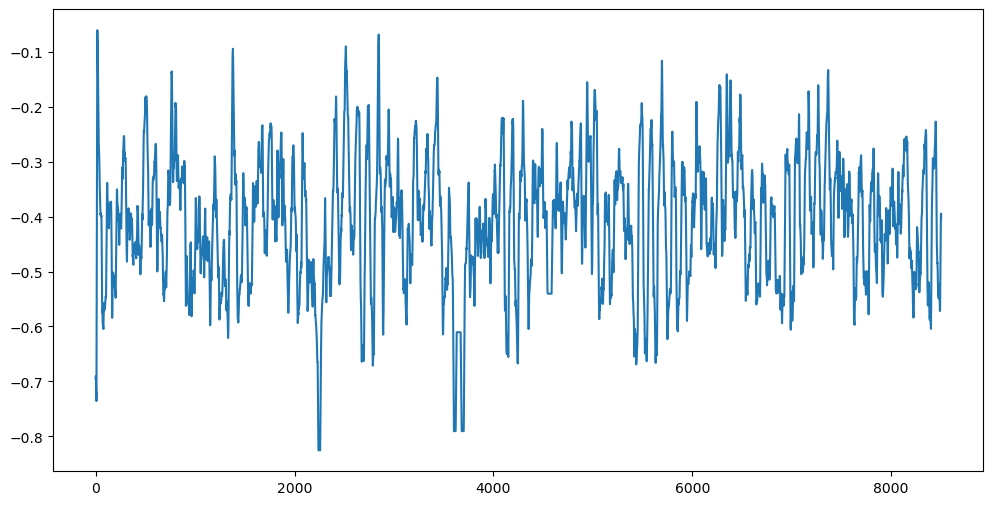

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.plot(df.index , df.rmean)


Let us use a random forest ensemble.

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.model_selection import TimeSeriesSplit

In [21]:
df.columns = df.columns.astype(str) 
#Converts all column names to string type. If there is a mix of str and int, fitting gives an error

In [29]:
preprocess = ColumnTransformer(transformers=[
                                    ("pca",PCA(n_components=10),list(range(1,25)))
                                    ], remainder="passthrough")

model = Pipeline(steps=[
                        ("preprocessing", preprocess),
                        ("model", RandomForestClassifier(n_estimators=100,max_depth=10,class_weight="balanced_subsample"))
                        ])

In [30]:
X= df.drop("target", axis=1)
y= df["target"]

In [31]:
#Dataframe to record the errors
row_names = [f"Fold {i+1}" for i in range(20)]
col_names = ["Precision","Recall", "F1", "False Alarm Rate"]
error = pd.DataFrame(np.nan ,index = row_names, columns = col_names)

i=0
tss = TimeSeriesSplit(n_splits = 20)
for train_index, test_index in tss.split(df):
    X_train = X.iloc[train_index]
    y_train = y.iloc[train_index]
    X_test = X.iloc[test_index]
    y_test = y.iloc[test_index]

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    error.iloc[i,0] = precision_score(y_test, y_pred, zero_division=0.0)
    error.iloc[i,1] = recall_score(y_test,y_pred, zero_division=0.0)
    error.iloc[i,2] = f1_score(y_test,y_pred, zero_division=0.0)
    error.iloc[i,3] = fp/(fp + tn) if (fp + tn)>0 else 0.0
    i+=1

print(error)


         Precision    Recall        F1  False Alarm Rate
Fold 1    0.000000  0.000000  0.000000          0.000000
Fold 2    0.000000  0.000000  0.000000          0.000000
Fold 3    0.000000  0.000000  0.000000          0.000000
Fold 4    0.000000  0.000000  0.000000          0.000000
Fold 5    0.000000  0.000000  0.000000          0.000000
Fold 6    0.000000  0.000000  0.000000          0.002469
Fold 7    0.000000  0.000000  0.000000          0.000000
Fold 8    0.000000  0.000000  0.000000          0.000000
Fold 9    0.704545  0.462687  0.558559          0.095941
Fold 10   0.000000  0.000000  0.000000          0.000000
Fold 11   0.000000  0.000000  0.000000          0.041237
Fold 12   0.000000  0.000000  0.000000          0.113580
Fold 13   0.000000  0.000000  0.000000          0.000000
Fold 14   0.000000  0.000000  0.000000          0.009877
Fold 15   0.000000  0.000000  0.000000          0.002469
Fold 16   0.000000  0.000000  0.000000          0.049383
Fold 17   0.000000  0.000000  0

We get a lot of zeroes since a lot of our test set don't contain any anomalies! Let us predict the model now on our whole data set. Note that this is not super useful as we are testing on our training data.

In [32]:
print(f"Overall Precision = {precision_score(y,model.predict(X))}")
print(f"Overall Recall = {recall_score(y,model.predict(X))}")
print(f"Overall F1 score = {f1_score(y,model.predict(X))}")

Overall Precision = 0.9182879377431906
Overall Recall = 0.946524064171123
Overall F1 score = 0.9321922317314022


Seems like the model performs wonderfully well, however this is deceptive as we had major data leakage. Let us perform the whole thing again, but this time we will splice our data to timestamp 3000. This will be our training set.

In [34]:
#Dataframe to record the errors
Xt = X.iloc[:3000]  #X train
yt = y.iloc[:3000]  #y train
Xho = X.iloc[3000:]  # X hold out
yho = y.iloc[3000:]   #y hold out
tss = TimeSeriesSplit(n_splits = 20)
i=0

for train_index, test_index in tss.split(df.iloc[:3000]):
    Xt_train = Xt.iloc[train_index]
    yt_train = yt.iloc[train_index]
    Xt_test = Xt.iloc[test_index]
    yt_test = yt.iloc[test_index]

    model.fit(Xt_train, yt_train)
    yt_pred = model.predict(Xt_test)

    tn, fp, fn, tp = confusion_matrix(yt_test, yt_pred, labels=[0, 1]).ravel()

    error.iloc[i,0] = precision_score(yt_test, yt_pred, zero_division=0.0)
    error.iloc[i,1] = recall_score(yt_test,yt_pred, zero_division=0.0)
    error.iloc[i,2] = f1_score(yt_test,yt_pred, zero_division=0.0)
    error.iloc[i,3] = fp/(fp + tn) if (fp + tn)>0 else 0.0
    i+=1

print(error)

print(f"Overall Precision on holdout= {precision_score(yho,model.predict(Xho))}")
print(f"Overall Recall on holdout= {recall_score(yho,model.predict(Xho))}")
print(f"Overall F1 score on holdout= {f1_score(yho,model.predict(Xho))}")

         Precision    Recall        F1  False Alarm Rate
Fold 1         0.0  0.000000  0.000000          0.000000
Fold 2         0.0  0.000000  0.000000          0.000000
Fold 3         0.0  0.000000  0.000000          0.000000
Fold 4         0.0  0.000000  0.000000          0.000000
Fold 5         0.0  0.000000  0.000000          0.000000
Fold 6         0.0  0.000000  0.000000          0.000000
Fold 7         0.0  0.000000  0.000000          0.000000
Fold 8         0.0  0.000000  0.000000          0.000000
Fold 9         0.0  0.000000  0.000000          0.000000
Fold 10        0.0  0.000000  0.000000          0.000000
Fold 11        0.0  0.000000  0.000000          0.000000
Fold 12        0.0  0.000000  0.000000          0.000000
Fold 13        0.0  0.000000  0.000000          0.000000
Fold 14        0.0  0.000000  0.000000          0.000000
Fold 15        0.0  0.000000  0.000000          0.000000
Fold 16        1.0  0.067797  0.126984          0.000000
Fold 17        0.0  0.000000  0